In [1]:

from evo_pathfinding_gen_sm.geometry import Environment, Mount, Grid, Blob
from evo_pathfinding_gen_sm.rendering.renderer import render_environment, render_phenotype, render_genotype, render_genotype_field, render_flow_field
from evo_pathfinding_gen_sm.genetic_algorithm.genetic_code import Phenotype, Genotype
from evo_pathfinding_gen_sm.genetic_algorithm.genetic_processes import mutate_shift, mutate_invert, uniform_crossover

from evo_pathfinding_gen_sm.genetic_algorithm.fitness import find_fitness
from evo_pathfinding_gen_sm.structural_simulator import StructuralSimulator
from evo_pathfinding_gen_sm.pathfinding.grid_pathfinder import GridPathfinder
from evo_pathfinding_gen_sm.pathfinding.prm_pathfinder import PRMPathfinder
import matplotlib.pyplot as plt
import shapely.plotting as plotting
import shapely
import numpy as np
import networkx as nx
import yaml

#with open("config/config.yaml") as f:
#    cfg = yaml.load(f, Loader=yaml.FullLoader)

{'bend_cost': 1, 'mass_cost': 100, 'deflection_cost': 100000}


In [2]:
mount1_plate = shapely.geometry.LineString([(4, 2), (4, 1)])
mount2_plate = shapely.geometry.LineString([(16, 6), (16, 8)])



env = Environment(
    area=(-5, 0, 25, 10),
    obstacles=[
        shapely.geometry.box(13, 4, 16, 10),
        shapely.geometry.box(4, 0, 6, 8),
        shapely.geometry.box(0, 4, 5, 8),
        shapely.geometry.box(15, 4, 18, 5),

    ],
    mount1=Mount(mount1_plate.coords[0], mount1_plate.coords[1], thickness=0.5),
    mount2=Mount(mount2_plate.coords[0], mount2_plate.coords[1], thickness=0.5),
    thickness=0.5
)

start_node = next((n for n, d in env.grid.graph.nodes(data=True) if d.get('start')), None)
target_node = next((n for n, d in env.grid.graph.nodes(data=True) if d.get('target')), None)


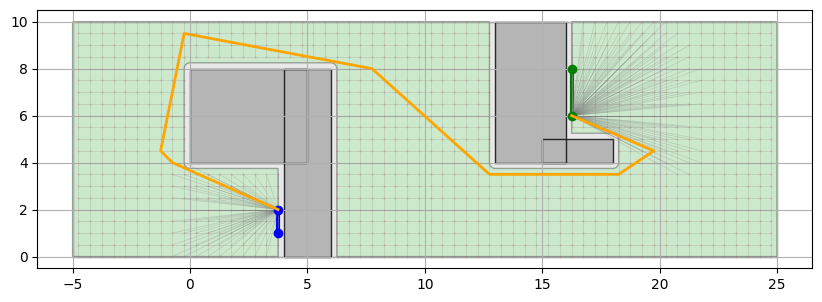

In [3]:
path2 = []
pathfinder2 = GridPathfinder(env)
path = pathfinder2.find_path(start_node,target_node)
render_environment(env,path)

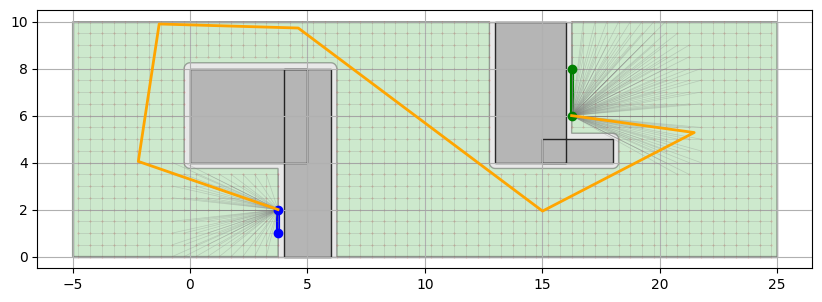

In [4]:

pathfinder = PRMPathfinder(env)
pathfinder.build_roadmap(node_count=100,n = 5000)
path = pathfinder.find_path(start_node, target_node)

while path == []:
    pathfinder.build_roadmap(node_count=100,n = 5000)
    path = pathfinder.find_path(start_node, target_node)
render_environment(env,path)

In [5]:
phenotype = Phenotype(env,path)
print(phenotype.nodes)
print("fitness:" + str(find_fitness(phenotype)))

[<POINT (3.75 2)>, <POINT (-2.201 4.05)>, <POINT (-1.312 9.902)>, <POINT (4.609 9.73)>, <POINT (15.012 1.935)>, <POINT (21.468 5.28)>, <POINT (16.25 6)>]
fitness:-50.469207467306944


In [6]:
pathfinder.build_roadmap(node_count=100,n = 5000)
path = pathfinder.find_path(start_node, target_node)

phenotype2 = Phenotype(env,path)


# Mutation (invert):

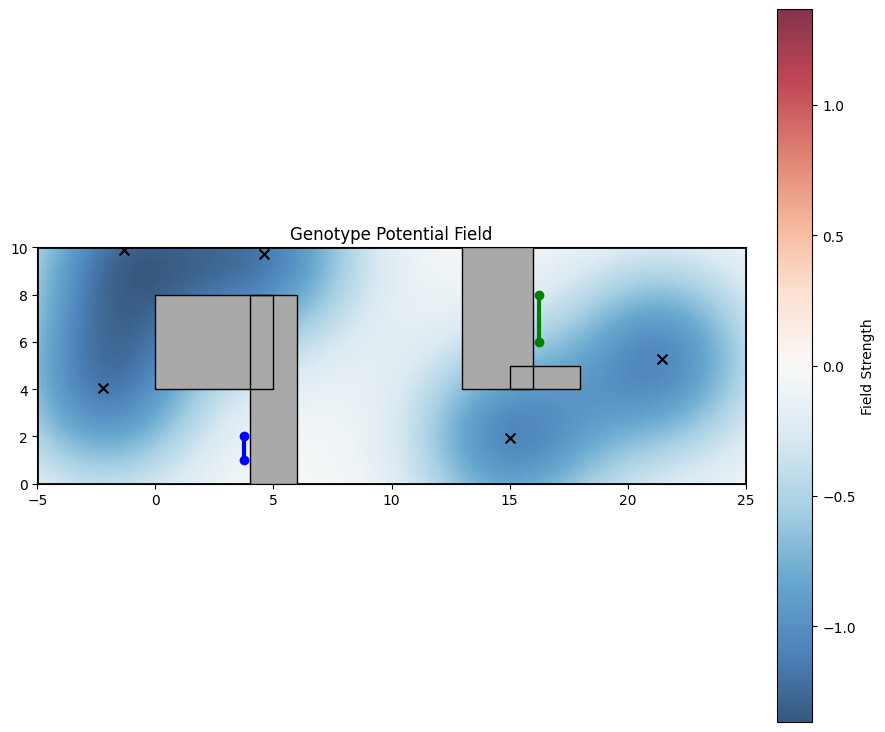

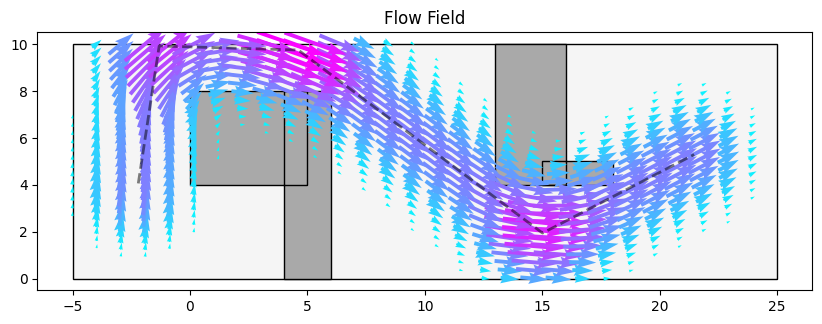

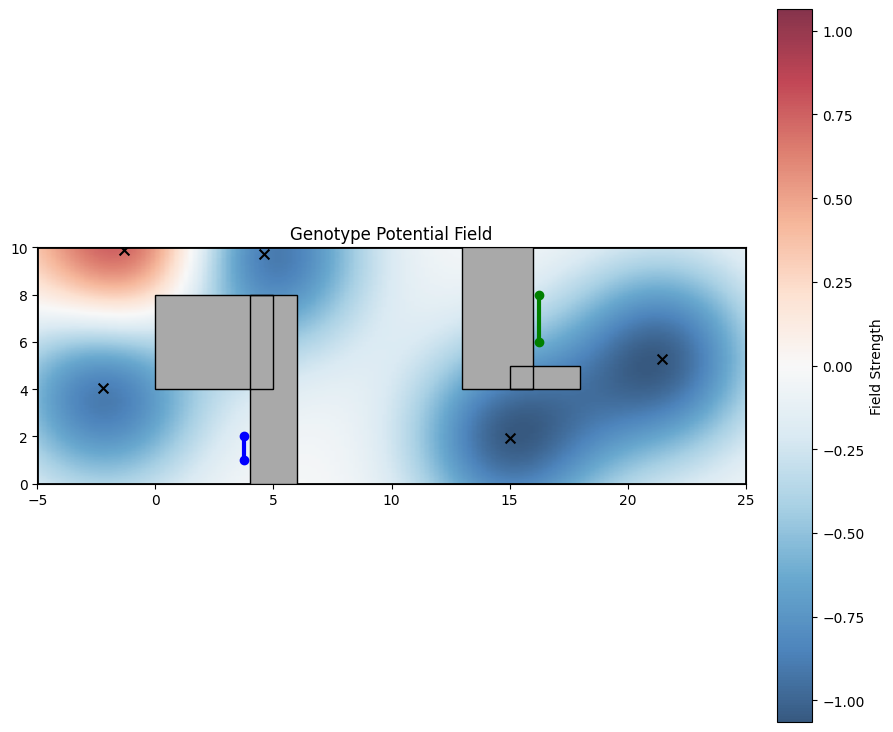

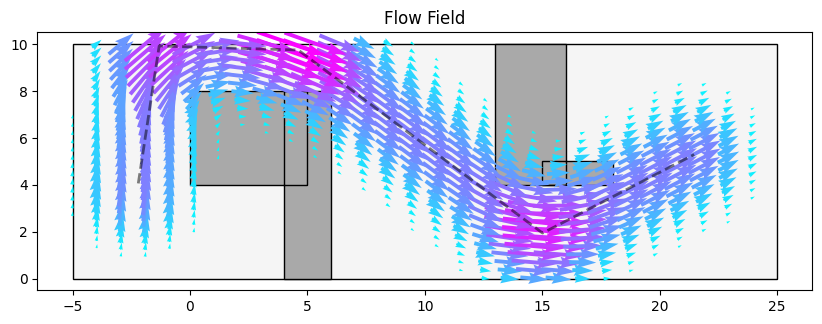

In [7]:
genotype = Genotype(phenotype.bends)
render_genotype_field(env,genotype)
render_flow_field(env,phenotype)

new_genotype = mutate_invert(genotype)
render_genotype_field(env,new_genotype)
pathfinder.get_phenotype_from_genotype(new_genotype)
render_flow_field(env,phenotype)



# Mutation (shift):

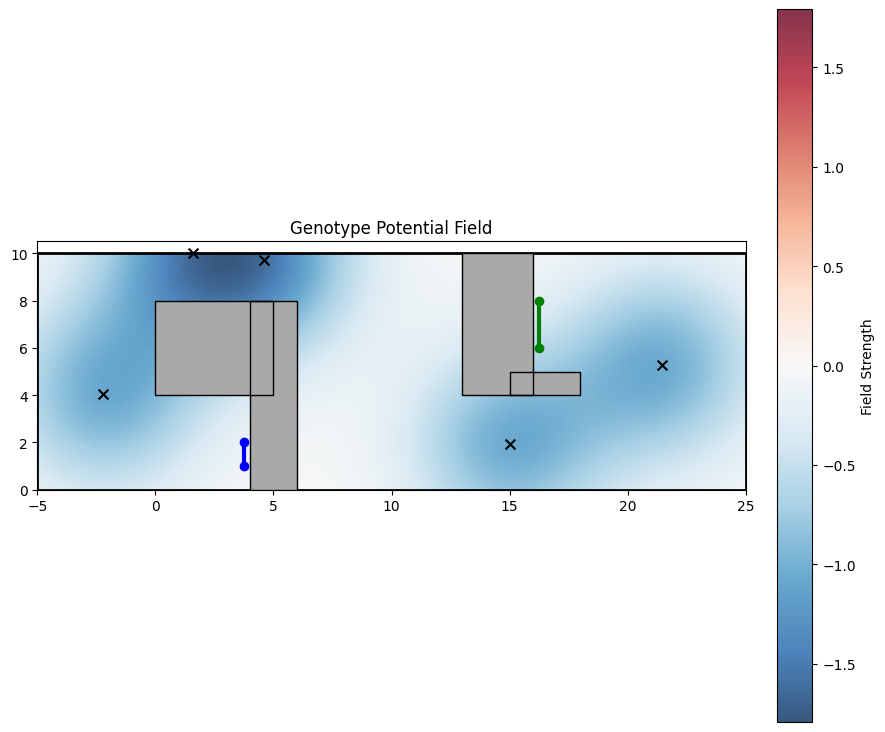

In [8]:
new_genotype = mutate_shift(genotype)
render_genotype_field(env,new_genotype)

# Crossover:

### Parent 1:

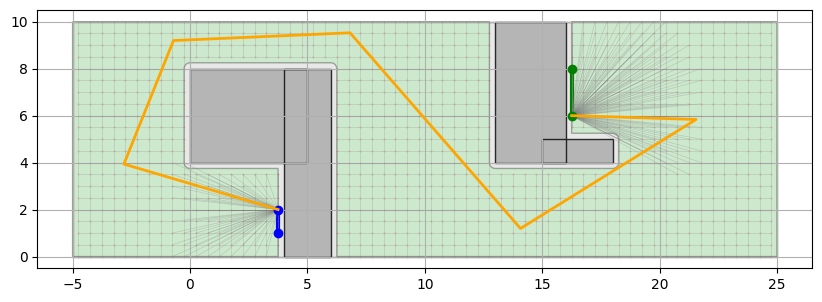

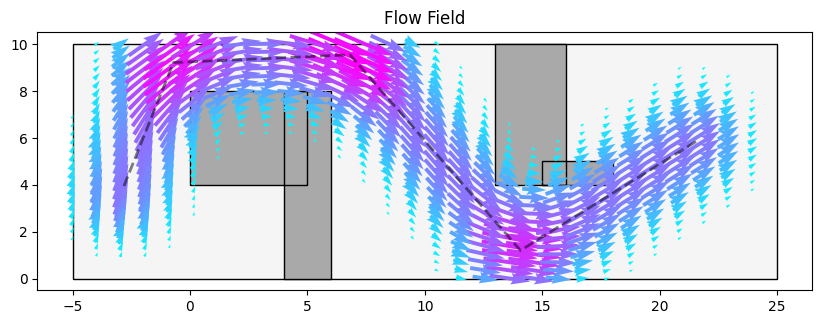

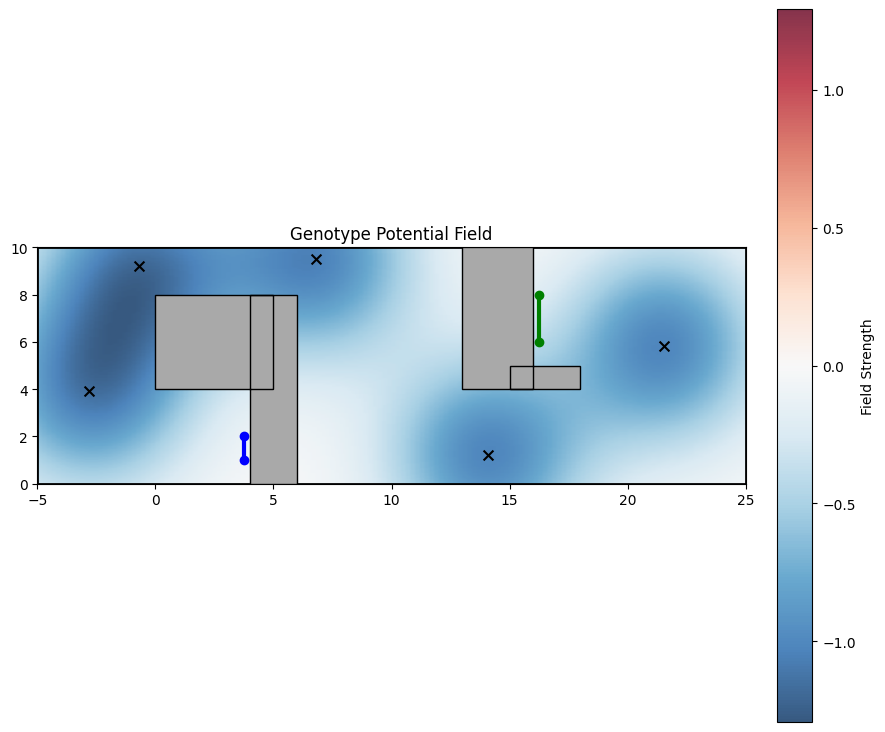

In [9]:
pathfinder.build_roadmap(node_count=100,n = 5000)
path = pathfinder.find_path(start_node, target_node)
render_environment(env,path)
phenotype4 = Phenotype(env,path)
render_flow_field(env,phenotype4)
genotype_a = Genotype(phenotype4.bends)
render_genotype_field(env,genotype_a)

### Parent 2:

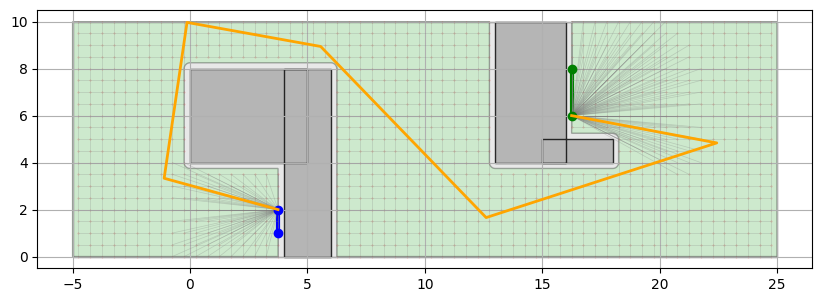

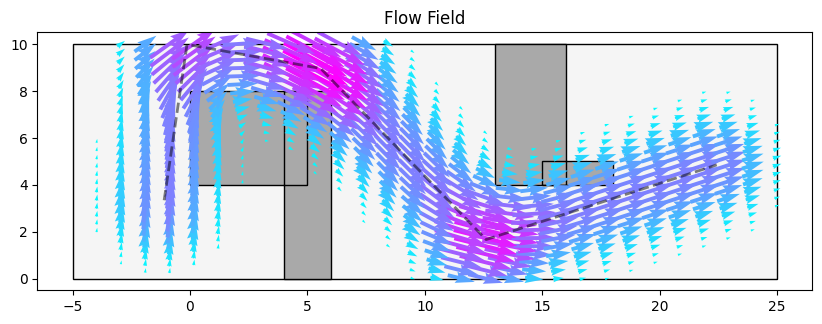

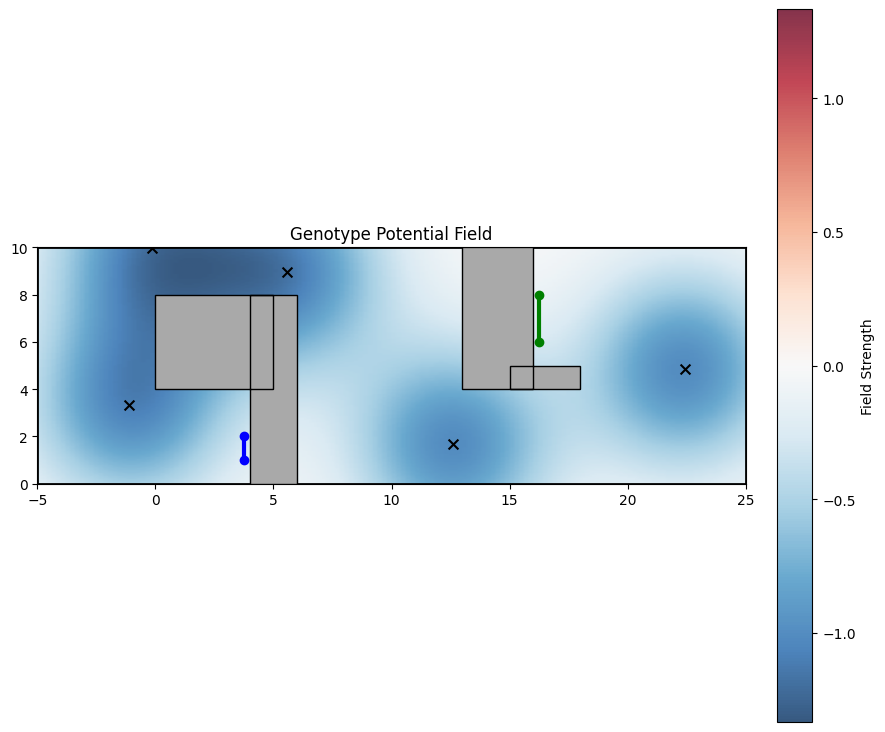

In [10]:
pathfinder.build_roadmap(node_count=100,n = 5000)
path = pathfinder.find_path(start_node, target_node)
render_environment(env,path)
phenotype5 = Phenotype(env,path)
render_flow_field(env,phenotype5)

genotype_b = Genotype(phenotype5.bends)
render_genotype_field(env,genotype_b)

## Children:

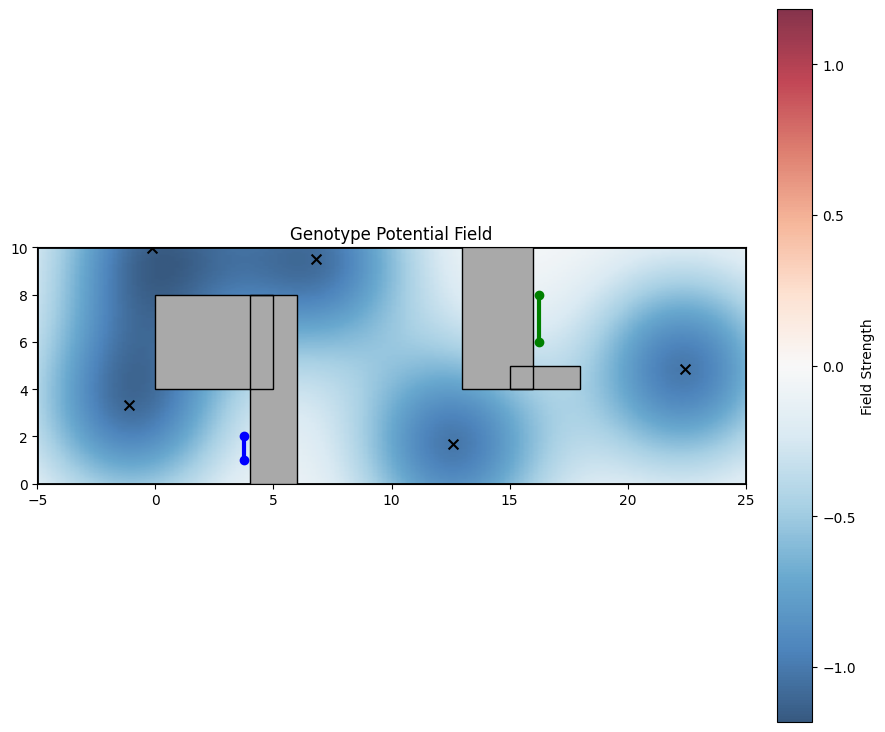

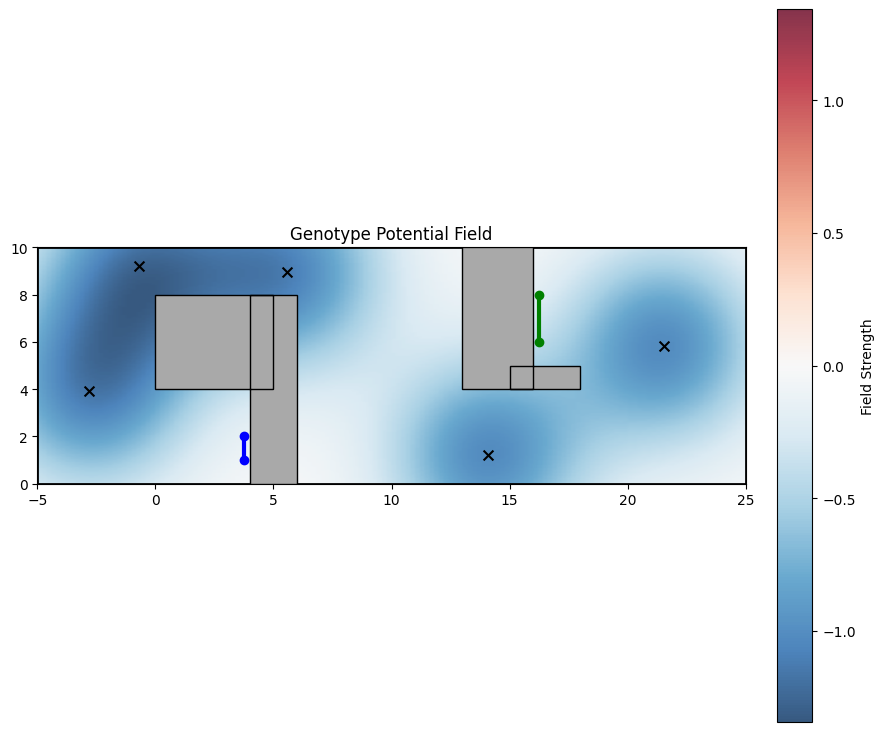

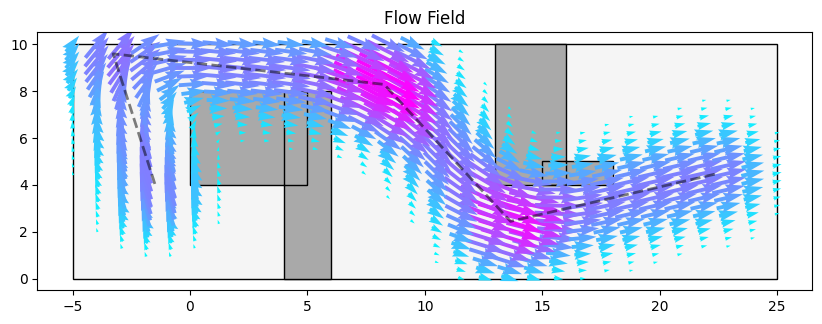

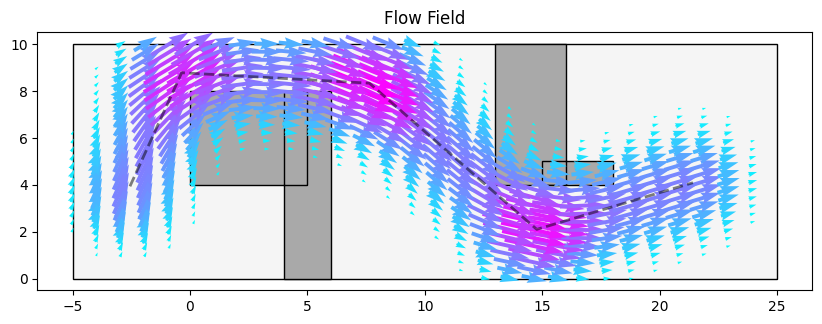

In [11]:
child1, child2 = uniform_crossover(genotype_a,genotype_b)
render_genotype_field(env,child1)
render_genotype_field(env,child2)
phenotype = pathfinder.get_phenotype_from_genotype(child1)
render_flow_field(env,phenotype)
phenotype = pathfinder.get_phenotype_from_genotype(child2)
render_flow_field(env,phenotype)